# Testing models with sample feature map

In [267]:
# Import pytorch
import torch
from torch import nn
import random
# Import torch vision
import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor

# Import matplotlib
import matplotlib.pyplot as plt

# Check versions
print(torch.__version__, torchvision.__version__)

2.5.1 0.20.1+cpu


In [268]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

Loading the sample

In [269]:

test_sample = torch.load("../samples/perturbed/deepfool09/test2_real.pt")
print(test_sample.shape)

torch.Size([16, 32, 32])


C:\Users\user\AppData\Local\Temp\ipykernel_5972\3161131794.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  test_sample = torch.load("../samples/perturbed/deepfool09/test

In [270]:
def display_feature_map(layer):
    print(layer.shape)
    # Averaging across the channels
    plt.imshow(((torch.sum(layer, 0) / layer.shape[0])).cpu())
    plt.axis("off")

torch.Size([16, 32, 32])


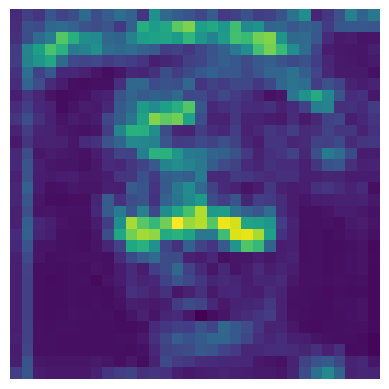

In [271]:
display_feature_map(test_sample)

Loading the model

In [272]:
class Model_2(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            # Create a conv layer
            nn.Conv2d(in_channels=input_shape,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1), # hyperparameters
            nn.ReLU(),
            nn.BatchNorm2d(hidden_units),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout(0.5),
        )
        self.layer_stack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(2560, hidden_units),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(hidden_units, output_shape),
        )
    def forward(self, x):
        x = self.conv_block_1(x)
        x = self.layer_stack(x)
        return x

In [273]:
model = Model_2(input_shape=1, hidden_units=10, output_shape=1).to(device)
model.load_state_dict(torch.load("../models/max_pool_layer_1_generalisability/model_3.pth"))

C:\Users\user\AppData\Local\Temp\ipykernel_5972\606778952.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("../models/max_pool_layer_1_ge

<All keys matched successfully>

Inference on sample

In [274]:
test_sample = (torch.sum(test_sample, 0) / test_sample.shape[0]).unsqueeze(0)
print(test_sample.shape) # torch.Size([1, 32, 32])

torch.Size([1, 32, 32])


In [275]:
with torch.inference_mode():
    model.eval()
    y_logit = model(test_sample.unsqueeze(0)) # model predicts in batches
    y_pred = torch.sigmoid(y_logit)
    print("Prediction:", y_pred.item())
    y_label = (y_pred > 0.5).float()

    if y_label == 1:
        print("The sample is perturbed.")
    else:
        print("The sample is not perturbed.")

Prediction: 0.9999740123748779
The sample is perturbed.
